# Project 02: Seed-free Graph Matching with Frank-Wolfe QAP (FAQ)

**Goal:** recover the one-to-one mapping between anonymized graph A and auxiliary graph B with **no known seed pairs**.

**Method (own implementation, numpy/scipy only).** Find the permutation that makes the two edge sets agree as much as possible:

`maximise  f(P) = trace(A P B P^T)`  over permutation matrices `P`.

The problem is relaxed to doubly-stochastic `P` and solved with **Frank-Wolfe**: each iteration computes the gradient `A P B`, solves one `linear_sum_assignment` on it to get a direction, takes the exact line-search step (the objective is quadratic along the segment) and moves. The result is projected back to a permutation with one more assignment. With no seeds, the start point matters: `P0 = (1 - lam) J/n + lam * Perm`, where `Perm` is the Hungarian matching of **structural fingerprints** (degree, triangles, sorted neighbour degrees and neighbour triangle counts). Each match's confidence is its number of consistent neighbour pairs; matches below `tau` can be rejected.

**Protocol:** the supplied noise is tiny, so real-data F1 is saturated. Tuning therefore uses a **stress test** (extra random edge replacement on B, ground truth unchanged): mean F1 over Train at extra noise 0/5/10%. Val is used once to confirm, the configuration is frozen in `config.json`, then Test is predicted. Test truth is never read.

**Notebook map:** 1 Setup, 2 Fingerprints, 3 FAQ, 4 Experiment helpers, 5 Tuning and freeze, 6 FAQ results, 7 Confidence, 8 Test predictions, 9 Comparison with other methods, Takeaways.

## 1. Setup, data loading and metrics
Precision = correct / predicted, recall = correct / n, F1, coverage = predicted / n, computed per instance and averaged over instances. `consistency` (matched neighbour pairs of a predicted pair) is a method-independent confidence; `reject` drops pairs below `tau`.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_free')
RESULTS = Path('results'); FIGS = RESULTS / 'figs'; FIGS.mkdir(parents=True, exist_ok=True)

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency, no self-loops."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def load_instance(split, name):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    truth = None
    if (d / "ground_truth.csv").exists():  # absent for test
        t = pd.read_csv(d / "ground_truth.csv")
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, truth, meta


def evaluate(pred, truth, n):
    """P/R/F1/coverage of one instance."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return dict(precision=p, recall=r, f1=f1, coverage=len(pred) / n)


def consistency(A, B, pred):
    """Per pair: # matched neighbour pairs (confidence)."""
    if not pred:
        return {}
    P = sp.csr_matrix((np.ones(len(pred)), (list(pred.keys()), list(pred.values()))), shape=(A.shape[0], B.shape[0]))
    V = (A @ P @ B.T).tocsr()
    return {a: float(V[a, b]) for a, b in pred.items()}


def reject(A, B, pred, tau):
    """Drop pairs with consistency < tau."""
    if tau is None or tau <= 0:
        return dict(pred)
    c = consistency(A, B, pred)
    return {a: b for a, b in pred.items() if c[a] >= tau}


print({s: len(list_instances(s)) for s in ['train', 'val', 'test']})
meta = pd.DataFrame([dict(split=s, **{k: load_instance(s, n)[3][k] for k in ['difficulty', 'edge_retention', 'added_edge_fraction']})
                     for s in ['train', 'val', 'test'] for n in list_instances(s)])
display(meta.groupby(['split', 'difficulty'])[['edge_retention', 'added_edge_fraction']].mean().round(4))

{'train': 27, 'val': 9, 'test': 18}


edge_retention  added_edge_fraction
split difficulty                                     
test  easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030
train easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030
val   easy                0.9996               0.0004
      hard                0.9945               0.0055
      medium              0.9970               0.0030

Real noise is tiny (0.05-0.55% of edges replaced, same node set), so B is almost an exact relabelling of A and good methods are at ceiling on the supplied splits. The stress test (`perturb`, section 4) adds extra random edge replacement on B to separate methods.

## 2. Structural fingerprints
Per node: degree, triangle count, sorted neighbour degrees and sorted neighbour triangle counts. The dissimilarity is the block-wise L1 distance, each block rescaled by its mean magnitude. FAQ uses its Hungarian matching as the start point.

In [3]:
def _triangles(A):
    return np.asarray(A.multiply(A @ A).sum(1)).ravel() / 2.0


def _sorted_nbr_values(A, x, width):
    """Neighbours' values of x, sorted desc, zero-padded."""
    out = np.zeros((A.shape[0], width), np.float32)
    for u in range(A.shape[0]):
        v = np.sort(x[A.indices[A.indptr[u]:A.indptr[u + 1]]])[::-1]
        out[u, :len(v)] = v
    return out


def fingerprints(A, B):
    """Feature blocks for both graphs."""
    dA, dB = np.asarray(A.sum(1)).ravel(), np.asarray(B.sum(1)).ravel()
    tA, tB = _triangles(A), _triangles(B)
    w = int(max(dA.max(), dB.max()))
    return {
        "deg": (dA[:, None], dB[:, None]),
        "tri": (tA[:, None], tB[:, None]),
        "nbr_deg": (_sorted_nbr_values(A, dA, w), _sorted_nbr_values(B, dB, w)),
        "nbr_tri": (_sorted_nbr_values(A, tA, w), _sorted_nbr_values(B, tB, w)),
    }


DEFAULT_WEIGHTS = dict(deg=1.0, tri=1.0, nbr_deg=1.0, nbr_tri=1.0)


def fingerprint_cost(A, B, weights=None):
    """n x n weighted, rescaled L1 dissimilarity."""
    weights = weights or DEFAULT_WEIGHTS
    C = np.zeros((A.shape[0], B.shape[0]), np.float32)
    for name, (fa, fb) in fingerprints(A, B).items():
        w = weights.get(name, 0.0)
        if w == 0:
            continue
        scale = max(0.5 * (np.abs(fa).sum(1).mean() + np.abs(fb).sum(1).mean()), 1e-9)
        C += (w / scale) * cdist(fa, fb, "cityblock").astype(np.float32)
    return C

## 3. FAQ (main method)
Start `P0 = (1 - init_lambda) J/n + init_lambda * Perm(fingerprint Hungarian)`. Each iteration: gradient `G = A P B`, direction `Q - P` from one assignment on `G`, exact line search, update. Stops when the step or the Frank-Wolfe gap vanishes, or after `iters` iterations.

In [4]:
def _sandwich(A, X, B):
    """A @ X @ B for sparse A, B."""
    return (B.T @ (A @ X).T).T


def match_faq(A, B, iters=30, init_lambda=0.5, tol=1e-6, weights=None, C=None):
    """Frank-Wolfe on the relaxed QAP max tr(A P B P^T)."""
    n = A.shape[0]
    C = fingerprint_cost(A, B, weights) if C is None else C
    ra, cb = linear_sum_assignment(C)
    P0 = np.zeros((n, n)); P0[ra, cb] = 1.0
    P = (1 - init_lambda) * np.full((n, n), 1.0 / n) + init_lambda * P0
    for _ in range(iters):
        G = _sandwich(A, P, B)
        ri, ci = linear_sum_assignment(-G)
        Q = np.zeros((n, n)); Q[ri, ci] = 1.0
        D = Q - P
        a1 = 2.0 * float((G * D).sum())
        a2 = float((_sandwich(A, D, B) * D).sum())
        if a2 < 0:
            alpha = float(np.clip(-a1 / (2 * a2), 0.0, 1.0))
        else:
            alpha = 1.0 if a1 + a2 > 0 else 0.0
        if alpha * np.abs(D).max() < tol or a1 <= tol:
            break
        P = P + alpha * D
    ra, cb = linear_sum_assignment(-P)
    return {int(a): int(b) for a, b in zip(ra, cb)}

## 4. Experiment helpers
`perturb` replaces a fraction of B's edges at random (deterministic, ground truth unchanged); noise 0 is the real data. `run_stress` runs one method on one instance at one noise level; `tune` runs a grid on Train and ranks by mean F1 (ties by runtime). Matchers are registered in `METHODS`; the comparison methods are added in section 9.

In [5]:
METHODS = {"faq": match_faq}
TUNE_NOISE = [0.0, 0.05, 0.10]
EVAL_NOISE = [0.0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]


def perturb(B, frac, seed=0):
    """Replace `frac` of B's edges with random non-edges."""
    rng = np.random.default_rng(seed)
    n = B.shape[0]
    iu = sp.triu(B, 1).tocoo()
    edges = np.column_stack([iu.row, iu.col])
    k = int(round(frac * len(edges)))
    if k == 0:
        return B
    keep = np.ones(len(edges), bool)
    keep[rng.choice(len(edges), k, replace=False)] = False
    existing = set(map(tuple, edges.tolist()))
    new = set()
    while len(new) < k:
        u, v = sorted(rng.integers(0, n, 2).tolist())
        if u != v and (u, v) not in existing and (u, v) not in new:
            new.add((u, v))
    e = np.vstack([edges[keep], np.array(sorted(new))])
    m = sp.coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(n, n))
    return (m + m.T).tocsr()


def run_stress(split, name, method, params, noise, tau=0, seed=0):
    """One run -> metrics row."""
    A, B, truth, meta = load_instance(split, name)
    B = perturb(B, noise, seed)
    t = time.perf_counter()
    pred = METHODS[method](A, B, **(params or {}))
    dt = time.perf_counter() - t
    pred = reject(A, B, pred, tau)
    row = evaluate(pred, truth, A.shape[0])
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=A.shape[0],
               method=method, params=json.dumps(params or {}, sort_keys=True), tau=tau, noise=noise, runtime=dt)
    return row


def run_grid(split, method, params, tau=0, noises=EVAL_NOISE):
    jobs = [(nm, z) for nm in list_instances(split) for z in noises]
    return pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_stress)(split, nm, method, params, z, tau) for nm, z in jobs))


def tune(method, grid, split='train', noises=TUNE_NOISE):
    """Grid on Train -> (ranked table, best cfg)."""
    jobs = [(nm, g, z) for nm in list_instances(split) for g in grid for z in noises]
    d = pd.DataFrame(Parallel(n_jobs=-1)(delayed(run_stress)(split, nm, method, g.get('params'), z, g.get('tau', 0)) for nm, g, z in jobs))
    d['cfg'] = [json.dumps(dict(params=json.loads(p), tau=t), sort_keys=True) for p, t in zip(d.params, d.tau)]
    s = d.groupby('cfg')[['f1', 'precision', 'recall', 'coverage', 'runtime']].mean().sort_values(['f1', 'runtime'], ascending=[False, True])
    return s.join(d.pivot_table(index='cfg', columns='noise', values='f1').add_prefix('f1@')), json.loads(s.index[0])

## 5. Tuning on Train, confirmation on Val, freeze
Stage 1: start blend `init_lambda` x maximum iterations. Stage 2: rejection threshold `tau` on top of the best stage-1 config. Both scored by mean Train F1 at extra noise 0/5/10%.

In [6]:
t0 = time.perf_counter()
tbl1, best1 = tune('faq', [dict(params=dict(init_lambda=l, iters=it)) for l in (0.0, 0.5, 0.9) for it in (15, 30)])
display(Markdown('**Stage 1: init_lambda x iters**')); display(tbl1.round(3))
tbl2, best_cfg = tune('faq', [dict(params=best1['params'], tau=t) for t in (0, 1, 2, 3, 5)])
display(Markdown('**Stage 2: rejection threshold tau**')); display(tbl2.round(3))
print(f'tuning took {time.perf_counter() - t0:.0f}s | best Train config: {best_cfg}')

**Stage 1: init_lambda x iters**

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.282,1.000,1.000,0.892
"{""params"": {""init_lambda"": 0.9, ""iters"": 15}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.284,1.000,1.000,0.892
"{""params"": {""init_lambda"": 0.9, ""iters"": 30}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.351,1.000,1.000,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 30}, ""tau"": 0}",0.964,0.964,0.964,1.0,0.367,1.000,1.000,0.892
"{""params"": {""init_lambda"": 0.0, ""iters"": 30}, ""tau"": 0}",0.467,0.467,0.467,1.0,1.168,0.822,0.341,0.238
"{""params"": {""init_lambda"": 0.0, ""iters"": 15}, ""tau"": 0}",0.441,0.441,0.441,1.0,0.869,0.746,0.341,0.235


**Stage 2: rejection threshold tau**

,f1,precision,recall,coverage,runtime,f1@0.0,f1@0.05,f1@0.1
cfg,,,,,,,,
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 0}",0.964,0.964,0.964,1.000,0.262,1.0,1.000,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 1}",0.964,0.964,0.964,1.000,0.277,1.0,1.000,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 2}",0.964,0.964,0.964,1.000,0.272,1.0,1.000,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 3}",0.964,0.964,0.964,1.000,0.272,1.0,1.000,0.892
"{""params"": {""init_lambda"": 0.5, ""iters"": 15}, ""tau"": 5}",0.961,0.964,0.959,0.995,0.254,1.0,0.998,0.886


tuning took 34s | best Train config: {'params': {'init_lambda': 0.5, 'iters': 15}, 'tau': 0}


In [7]:
val_cmp = pd.concat([run_grid('val', 'faq', dict(init_lambda=0.0, iters=30), noises=TUNE_NOISE).assign(cfg='uniform start'),
                     run_grid('val', 'faq', best_cfg['params'], best_cfg['tau'], noises=TUNE_NOISE).assign(cfg='chosen')])
display(Markdown('**Val: chosen config vs uniform start (F1 by extra noise)**'))
display(val_cmp.pivot_table(index='cfg', columns='noise', values='f1').round(3))
key = json.dumps(best_cfg, sort_keys=True)
print(f"mean F1 of chosen config: Train {tbl2.loc[key, 'f1']:.3f} | Val {val_cmp[val_cmp.cfg == 'chosen'].f1.mean():.3f}")

FROZEN = dict(main_method='faq', faq_params=best_cfg['params'], tau=best_cfg['tau'],
              note='Chosen on Train only (mean F1 at extra-noise 0/5/10% on B); confirmed once on Val; frozen before Test.')
Path('config.json').write_text(json.dumps(FROZEN, indent=2))
print(Path('config.json').read_text())

**Val: chosen config vs uniform start (F1 by extra noise)**

noise,0.00,0.05,0.10
cfg,,,
chosen,1.000,1.00,0.891
uniform start,0.792,0.34,0.339


mean F1 of chosen config: Train 0.964 | Val 0.964
{
  "main_method": "faq",
  "faq_params": {
    "init_lambda": 0.5,
    "iters": 15
  },
  "tau": 0,
  "note": "Chosen on Train only (mean F1 at extra-noise 0/5/10% on B); confirmed once on Val; frozen before Test."
}


## 6. FAQ results (frozen config): Train + Val, real data and stress test
Per-instance rows are saved to `results/{train,val}_results.csv`.

In [8]:
cfg, tau = FROZEN['faq_params'], FROZEN['tau']
faq = pd.concat([run_grid(s, 'faq', cfg, tau) for s in ('train', 'val')], ignore_index=True)
for s in ('train', 'val'):
    faq[faq.split == s].to_csv(RESULTS / f'{s}_results.csv', index=False)
print(len(faq), 'runs saved to results/')

M = ['precision', 'recall', 'f1', 'coverage', 'runtime']
display(Markdown('**Real data (mean over instances)**'))
display(faq[faq.noise == 0].groupby('split')[M].mean().round(3))
display(Markdown('**F1 vs extra noise on B**'))
display(faq.pivot_table(index='split', columns='noise', values='f1').round(3))
display(Markdown('**F1 by family x extra noise (Train+Val)**'))
display(faq.pivot_table(index='family', columns='noise', values='f1').round(3))
display(Markdown('**F1 by difficulty x extra noise (Train+Val)**'))
display(faq.pivot_table(index='difficulty', columns='noise', values='f1').round(3))
display(Markdown('**Runtime (s) by size, real data**'))
display(faq[faq.noise == 0].groupby('n').runtime.agg(['mean', 'max']).round(2))

252 runs saved to results/


**Real data (mean over instances)**

,precision,recall,f1,coverage,runtime
split,,,,,
train,1.0,1.0,1.0,1.0,0.102
val,1.0,1.0,1.0,1.0,0.111


**F1 vs extra noise on B**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
split,,,,,,,
train,1.0,1.0,1.0,0.892,0.494,0.344,0.204
val,1.0,1.0,1.0,0.891,0.464,0.343,0.139


**F1 by family x extra noise (Train+Val)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
family,,,,,,,
erdos_renyi,1.0,1.0,1.0,0.675,0.100,0.013,0.008
preferential_attachment,1.0,1.0,1.0,1.000,1.000,1.000,0.547
stochastic_block,1.0,1.0,1.0,1.000,0.359,0.018,0.007


**F1 by difficulty x extra noise (Train+Val)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
difficulty,,,,,,,
easy,1.0,1.0,1.0,1.000,0.759,0.354,0.041
hard,1.0,1.0,1.0,0.675,0.342,0.336,0.313
medium,1.0,1.0,1.0,1.000,0.358,0.340,0.208


**Runtime (s) by size, real data**

,mean,max
n,,
300,0.01,0.02
600,0.06,0.07
1000,0.24,0.36


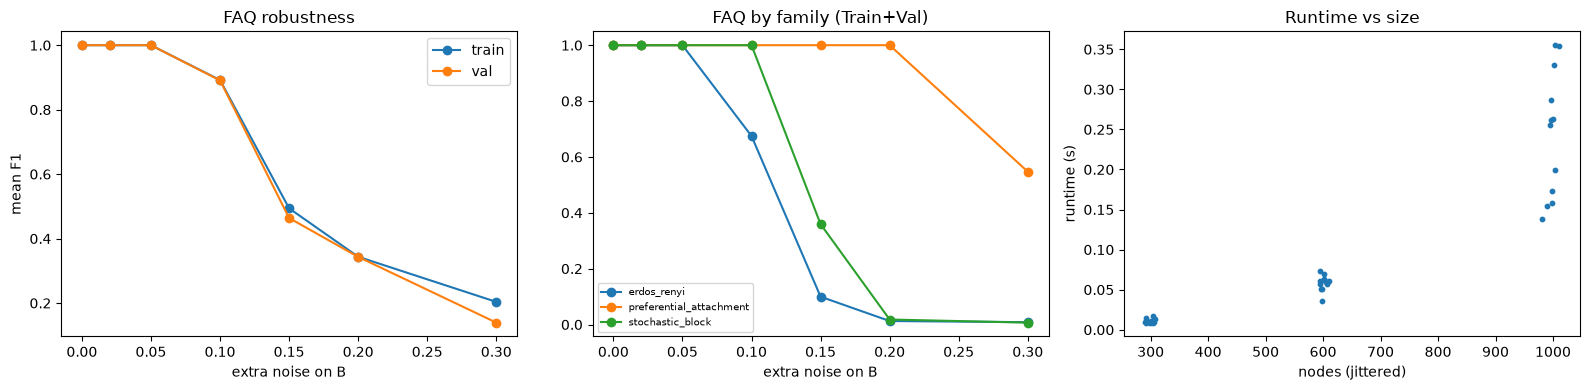

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s, g in faq.groupby('split'):
    ax[0].plot(*zip(*g.groupby('noise').f1.mean().items()), marker='o', label=s)
ax[0].set_xlabel('extra noise on B'); ax[0].set_ylabel('mean F1'); ax[0].set_title('FAQ robustness'); ax[0].legend()
for fam, g in faq.groupby('family'):
    ax[1].plot(*zip(*g.groupby('noise').f1.mean().items()), marker='o', label=fam)
ax[1].set_xlabel('extra noise on B'); ax[1].set_title('FAQ by family (Train+Val)'); ax[1].legend(fontsize=7)
r0 = faq[faq.noise == 0]
ax[2].scatter(r0.n + np.random.default_rng(0).normal(0, 8, len(r0)), r0.runtime, s=10)
ax[2].set_xlabel('nodes (jittered)'); ax[2].set_ylabel('runtime (s)'); ax[2].set_title('Runtime vs size')
plt.tight_layout(); plt.savefig(FIGS / 'robustness.png', dpi=130); plt.show()

## 7. Matching confidence (Val)
Accuracy of each matched pair as a function of its consistency votes, and the precision/coverage trade-off of a rejection threshold, at extra noise 10% and 15% (where FAQ makes errors).

accuracy  pairs
noise bin                                  
0.10  (0.0, 2.0]               0.500      2
      (2.0, 4.0]               1.000     56
      (4.0, 8.0]               0.880   1256
      (8.0, 16.0]              0.531   1589
      (16.0, 32.0]             0.928   1181
      (32.0, 1000000000.0]     1.000   1616
0.15  (0.0, 2.0]               0.250     16
      (2.0, 4.0]               0.563    261
      (4.0, 8.0]               0.518   2125
      (8.0, 16.0]              0.258   2781
      (16.0, 32.0]             0.576    465
      (32.0, 1000000000.0]     1.000     52

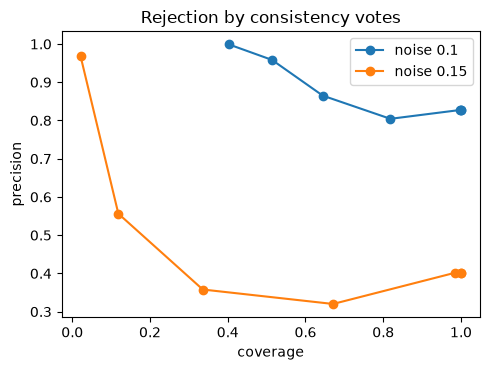

In [10]:
recs = []
for nm in list_instances('val'):
    A_, B_, tr_, mt_ = load_instance('val', nm)
    for z in (0.10, 0.15):
        Bz = perturb(B_, z, 0); p = match_faq(A_, Bz, **cfg); c = consistency(A_, Bz, p)
        recs += [dict(inst=nm, family=mt_['family'], noise=z, votes=c[a], correct=tr_[a] == b) for a, b in p.items()]
cf = pd.DataFrame(recs); cf['bin'] = pd.cut(cf.votes, [-1, 0, 2, 4, 8, 16, 32, 1e9])
display(cf.groupby(['noise', 'bin'], observed=True).correct.agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'pairs'}).round(3))
fig, ax = plt.subplots(figsize=(5, 3.8))
for z, g in cf.groupby('noise'):
    pts = [(len(g[g.votes >= t]) / len(g), g[g.votes >= t].correct.mean()) for t in (0, 2, 4, 8, 12, 16, 24)]
    ax.plot(*zip(*pts), marker='o', label=f'noise {z}')
ax.set_xlabel('coverage'); ax.set_ylabel('precision'); ax.legend(); ax.set_title('Rejection by consistency votes')
plt.tight_layout(); plt.savefig(FIGS / 'confidence.png', dpi=130); plt.show()

## 8. Test predictions (frozen config)
Config is read back from `config.json`; test truth is never accessed. `edge_overlap` (mean consistency / mean degree) is a label-free sanity score. Written files are re-read and checked against the submission format.

In [11]:
frozen = json.loads(Path('config.json').read_text())
PRED = Path('predictions'); summ = []
for nm in list_instances('test'):
    A_, B_, _, mt_ = load_instance('test', nm); n_ = A_.shape[0]
    t = time.perf_counter(); p = reject(A_, B_, match_faq(A_, B_, **frozen['faq_params']), frozen['tau']); dt = time.perf_counter() - t
    out = pd.DataFrame(sorted(p.items()), columns=['node_a', 'node_b'])
    (PRED / nm).mkdir(parents=True, exist_ok=True); out.to_csv(PRED / nm / 'predictions.csv', index=False)
    c = consistency(A_, B_, p)
    summ.append(dict(instance=nm, family=mt_['family'], difficulty=mt_['difficulty'], n=n_, predicted=len(out), coverage=len(out) / n_,
                     edge_overlap=np.mean(list(c.values())) / max(A_.sum() / n_, 1), runtime=dt))
ts = pd.DataFrame(summ); ts.to_csv(RESULTS / 'test_summary.csv', index=False); display(ts.round(3))

for nm in list_instances('test'):
    d = pd.read_csv(PRED / nm / 'predictions.csv'); n_ = len(pd.read_csv(DATA / 'test' / nm / 'nodes_a.csv'))
    assert list(d.columns) == ['node_a', 'node_b'] and d.node_a.is_unique and d.node_b.is_unique, nm
    assert d.node_a.between(0, n_ - 1).all() and d.node_b.between(0, n_ - 1).all(), nm
print('OK:', len(list(PRED.glob('*/predictions.csv'))), 'prediction files pass the format checks')

,instance,family,difficulty,n,predicted,coverage,edge_overlap,runtime
0,erdos_renyi_easy_00,erdos_renyi,easy,300,300,1.0,1.000,0.009
1,erdos_renyi_easy_01,erdos_renyi,easy,300,300,1.0,1.000,0.008
2,erdos_renyi_hard_00,erdos_renyi,hard,1000,1000,1.0,0.995,0.177
3,erdos_renyi_hard_01,erdos_renyi,hard,1000,1000,1.0,0.995,0.177
4,erdos_renyi_medium_00,erdos_renyi,medium,600,600,1.0,0.997,0.045
5,erdos_renyi_medium_01,erdos_renyi,medium,600,600,1.0,0.997,0.046
6,preferential_attachment_easy_00,preferential_attachment,easy,300,300,1.0,0.999,0.008
7,preferential_attachment_easy_01,preferential_attachment,easy,300,300,1.0,0.999,0.008
8,preferential_attachment_hard_00,preferential_attachment,hard,1000,1000,1.0,0.994,0.083
9,preferential_attachment_hard_01,preferential_attachment,hard,1000,1000,1.0,0.994,0.111


OK: 18 prediction files pass the format checks


## 9. Comparison with other methods
All methods run on the same Train+Val instances at every extra-noise level. Their configurations were tuned on Train earlier with the same protocol and are fixed here (no re-tuning):

| method | idea | frozen config |
|---|---|---|
| **bootstrap percolation** | Seeds = mutual-best fingerprint pairs with a margin; greedy percolation (match the pair with most matched-neighbour votes, add its votes); re-seed from high-vote matches; keep the seed size that preserves most A-edges; reject below `tau`. | `k_fracs=(0.01, 0.03, 0.1), r=2, reseed_votes=4, tau=3` |
| **FAQ-seeded percolation** (ablation) | Seeds = FAQ pairs with >= `seed_votes` consistent votes, then the same percolation + re-seed. | `seed_votes=12, r=1` |
| **IsoRank** | `R <- a (A D^-1) R (B D^-1)^T + (1-a) E`, `E` = fingerprint-similarity prior; Hungarian on `R`. | `alpha=0.8, prior_temp=0.3` |
| **fingerprint + Hungarian** | Linear assignment on the fingerprint dissimilarity. | default weights |

Per-instance rows of **all** methods (FAQ included) are saved to `results/comparison_results.csv` (column `method`).

In [12]:
def mutual_best_seeds(C, k):
    """Top-k mutual-best pairs by margin."""
    rb, cb = C.argmin(1), C.argmin(0)
    srow = np.partition(C, 1, axis=1)[:, :2]
    scol = np.partition(C, 1, axis=0)[:2, :]
    gap_r, gap_c = srow[:, 1] - srow[:, 0], scol[1, :] - scol[0, :]
    cand = [(min(gap_r[a], gap_c[rb[a]]), a, rb[a]) for a in range(C.shape[0]) if cb[rb[a]] == a]
    cand.sort(key=lambda t: -t[0])
    return {int(a): int(b) for g, a, b in cand[:k] if g > 0}


def percolate(A, B, seeds, r=1, tiebreak=None):
    """Greedy percolation -> (pred, votes at match time)."""
    n = A.shape[0]
    if tiebreak is None:
        dA, dB = np.asarray(A.sum(1)).ravel(), np.asarray(B.sum(1)).ravel()
        tiebreak = np.abs(dA[:, None] - dB[None, :]).astype(np.float32)
    tb = -0.49 * tiebreak / (float(tiebreak.max()) + 1e-9)
    P = sp.csr_matrix((np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n))
    S = (A @ P @ B.T).toarray().astype(np.float32) + tb.astype(np.float32)
    pred, votes = dict(seeds), {a: np.inf for a in seeds}
    for a, b in seeds.items():
        S[a, :] = -np.inf; S[:, b] = -np.inf
    while len(pred) < n:
        a, b = divmod(int(S.argmax()), n)
        v = S[a, b]
        if not np.isfinite(v) or round(float(v)) < r:
            break
        pred[a] = b; votes[a] = float(round(float(v)))
        S[a, :] = -np.inf; S[:, b] = -np.inf
        na = A.indices[A.indptr[a]:A.indptr[a + 1]]
        nb = B.indices[B.indptr[b]:B.indptr[b + 1]]
        S[np.ix_(na, nb)] += 1.0
    return pred, votes


def _overlap(A, B, pred):
    """Preserved A-edges (label-free score)."""
    return float(sum(consistency(A, B, pred).values())) / 2.0


def match_bootstrap(A, B, k_fracs=(0.05,), k_min=5, r=1, reseed_votes=3, rounds=1, weights=None, C=None):
    """Fingerprint seeds -> percolation -> re-seed; best seed size by edge overlap."""
    n = A.shape[0]
    C = fingerprint_cost(A, B, weights) if C is None else C
    best, best_score = None, -1.0
    for kf in k_fracs:
        pred, votes = percolate(A, B, mutual_best_seeds(C, max(k_min, int(round(kf * n)))), r=r, tiebreak=C)
        for _ in range(rounds):
            keep = {a: b for a, b in pred.items() if votes[a] >= reseed_votes}
            if len(keep) == len(pred) or not keep:
                break
            pred, votes = percolate(A, B, keep, r=r, tiebreak=C)
        score = _overlap(A, B, pred)
        if score > best_score:
            best, best_score = pred, score
    return best


def match_faq_perc(A, B, seed_votes=6, r=2, reseed_votes=4, init_lambda=0.5, iters=15):
    """FAQ high-confidence pairs as seeds -> percolation."""
    C = fingerprint_cost(A, B)
    p = match_faq(A, B, init_lambda=init_lambda, iters=iters, C=C)
    c = consistency(A, B, p)
    seeds = {a: b for a, b in p.items() if c[a] >= seed_votes}
    if not seeds:
        return p
    pred, votes = percolate(A, B, seeds, r=r, tiebreak=C)
    keep = {a: b for a, b in pred.items() if votes[a] >= reseed_votes}
    if keep and len(keep) < len(pred):
        pred, votes = percolate(A, B, keep, r=r, tiebreak=C)
    return pred


def match_isorank(A, B, alpha=0.8, iters=30, weights=None, C=None, prior_temp=0.1):
    """IsoRank with a fingerprint prior."""
    C = fingerprint_cost(A, B, weights) if C is None else C
    dA = np.maximum(np.asarray(A.sum(1)).ravel(), 1)
    dB = np.maximum(np.asarray(B.sum(1)).ravel(), 1)
    An = (A @ sp.diags(1.0 / dA)).tocsr()
    Bn = (B @ sp.diags(1.0 / dB)).tocsr()
    E = np.exp(-C / (prior_temp * (C.mean() + 1e-9))).astype(np.float64)
    E /= E.sum()
    R = E.copy()
    for _ in range(iters):
        R = alpha * (Bn @ (An @ R).T).T + (1 - alpha) * E
        R /= R.sum()
    ra, cb = linear_sum_assignment(-R)
    return {int(a): int(b) for a, b in zip(ra, cb)}


def match_fingerprint(A, B, weights=None, C=None):
    """Hungarian on the fingerprint cost."""
    ra, cb = linear_sum_assignment(fingerprint_cost(A, B, weights) if C is None else C)
    return {int(a): int(b) for a, b in zip(ra, cb)}


METHODS.update(bootstrap=match_bootstrap, faq_perc=match_faq_perc, isorank=match_isorank, fingerprint=match_fingerprint)
COMPARE_CFGS = {
    "bootstrap": (dict(k_fracs=[0.01, 0.03, 0.1], r=2, reseed_votes=4), 3),
    "faq_perc": (dict(seed_votes=12, r=1), 0),
    "isorank": (dict(alpha=0.8, prior_temp=0.3), 0),
    "fingerprint": (dict(weights=dict(deg=1, tri=1, nbr_deg=1.0, nbr_tri=1.0)), 0),
}

In [13]:
frames = [faq]
for s in ('train', 'val'):
    for m, (prm, t) in COMPARE_CFGS.items():
        frames.append(run_grid(s, m, prm, t))
allres = pd.concat(frames, ignore_index=True)
allres.to_csv(RESULTS / 'comparison_results.csv', index=False)
print(len(allres), 'runs saved to results/comparison_results.csv')

LABELS = {'faq': 'FAQ (main)', 'bootstrap': 'bootstrap percolation', 'faq_perc': 'FAQ-seeded percolation',
          'isorank': 'IsoRank', 'fingerprint': 'fingerprint + Hungarian'}
order = list(LABELS.values())
for s in ('val', 'train'):
    display(Markdown(f'**{s.capitalize()}: F1 vs extra noise on B (mean over instances)**'))
    display(allres[allres.split == s].pivot_table(index='method', columns='noise', values='f1').rename(index=LABELS).loc[order].round(3))
display(Markdown('**Real data, Train+Val: precision / recall / F1 / coverage / runtime**'))
display(allres[allres.noise == 0].groupby('method')[M].mean().rename(index=LABELS).loc[order].round(3))
display(Markdown('**Real data: F1 by difficulty (Train+Val)**'))
display(allres[allres.noise == 0].pivot_table(index='difficulty', columns='method', values='f1').rename(columns=LABELS)[order].round(3))
for z in (0.05, 0.10, 0.15):
    display(Markdown(f'**F1 by family at extra noise {z:.0%} (Train+Val)**'))
    display(allres[allres.noise == z].pivot_table(index='family', columns='method', values='f1').rename(columns=LABELS)[order].round(3))
display(Markdown('**Runtime (s) by size, real data**'))
display(allres[allres.noise == 0].pivot_table(index='n', columns='method', values='runtime').rename(columns=LABELS)[order].round(2))

w = allres.pivot_table(index=['split', 'instance', 'noise'], columns='method', values='f1').reset_index()
display(Markdown('**FAQ vs each method, per run: share where FAQ is better / equal (within 0.005) / worse, by extra noise**'))
display(pd.concat({LABELS[m]: w.groupby('noise').apply(lambda g: pd.Series(dict(
    better=((g.faq - g[m]) > 0.005).mean(), equal=((g.faq - g[m]).abs() <= 0.005).mean(), worse=((g.faq - g[m]) < -0.005).mean())),
    include_groups=False) for m in ('bootstrap', 'faq_perc')}, axis=1).round(2))

1260 runs saved to results/comparison_results.csv


**Val: F1 vs extra noise on B (mean over instances)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
method,,,,,,,
FAQ (main),1.000,1.000,1.000,0.891,0.464,0.343,0.139
bootstrap percolation,1.000,0.999,0.994,0.728,0.014,0.015,0.001
FAQ-seeded percolation,1.000,1.000,1.000,0.891,0.521,0.335,0.222
IsoRank,0.927,0.590,0.364,0.183,0.088,0.041,0.017
fingerprint + Hungarian,0.923,0.569,0.342,0.188,0.106,0.064,0.026


**Train: F1 vs extra noise on B (mean over instances)**

noise,0.00,0.02,0.05,0.10,0.15,0.20,0.30
method,,,,,,,
FAQ (main),1.000,1.000,1.000,0.892,0.494,0.344,0.204
bootstrap percolation,1.000,0.999,0.987,0.763,0.171,0.011,0.004
FAQ-seeded percolation,1.000,1.000,1.000,0.892,0.538,0.372,0.230
IsoRank,0.934,0.601,0.367,0.192,0.086,0.046,0.016
fingerprint + Hungarian,0.929,0.580,0.350,0.193,0.105,0.067,0.024


**Real data, Train+Val: precision / recall / F1 / coverage / runtime**

... (9 outputs left out)

**Runtime (s) by size, real data**

method,FAQ (main),bootstrap percolation,FAQ-seeded percolation,IsoRank,fingerprint + Hungarian
n,,,,,
300,0.01,0.06,0.02,0.03,0.01
600,0.06,0.35,0.10,0.28,0.03
1000,0.24,1.47,0.40,1.74,0.10


**FAQ vs each method, per run: share where FAQ is better / equal (within 0.005) / worse, by extra noise**

bootstrap percolation             FAQ-seeded percolation            
                     better equal worse                 better equal worse
noise                                                                     
0.00                   0.00  1.00  0.00                   0.00  1.00  0.00
0.02                   0.03  0.97  0.00                   0.00  1.00  0.00
0.05                   0.50  0.50  0.00                   0.00  1.00  0.00
0.10                   0.92  0.03  0.06                   0.06  0.92  0.03
0.15                   0.81  0.17  0.03                   0.11  0.78  0.11
0.20                   0.64  0.33  0.03                   0.19  0.75  0.06
0.30                   0.50  0.44  0.06                   0.22  0.58  0.19

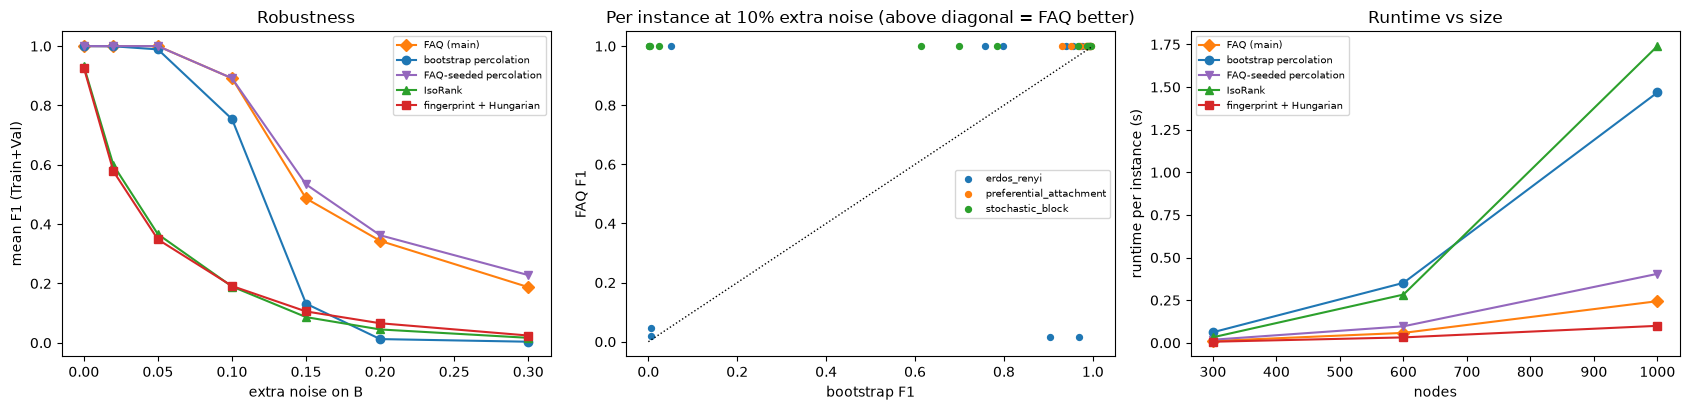

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
styles = {'faq': ('C1', 'D'), 'bootstrap': ('C0', 'o'), 'faq_perc': ('C4', 'v'), 'isorank': ('C2', '^'), 'fingerprint': ('C3', 's')}
for m, (c, mk) in styles.items():
    g = allres[allres.method == m].groupby('noise').f1.mean()
    ax[0].plot(g.index, g.values, marker=mk, c=c, label=LABELS[m])
ax[0].set_xlabel('extra noise on B'); ax[0].set_ylabel('mean F1 (Train+Val)'); ax[0].set_title('Robustness'); ax[0].legend(fontsize=7)
w10 = w[w.noise == 0.10].merge(allres[['instance', 'family']].drop_duplicates(), on='instance')
for fam, g in w10.groupby('family'):
    ax[1].scatter(g.bootstrap, g.faq, label=fam, s=18)
ax[1].plot([0, 1], [0, 1], 'k:', lw=1); ax[1].set_xlabel('bootstrap F1'); ax[1].set_ylabel('FAQ F1')
ax[1].set_title('Per instance at 10% extra noise (above diagonal = FAQ better)'); ax[1].legend(fontsize=7)
for m, (c, mk) in styles.items():
    g = allres[(allres.method == m) & (allres.noise == 0)].groupby('n').runtime.mean()
    ax[2].plot(g.index, g.values, marker=mk, c=c, label=LABELS[m])
ax[2].set_xlabel('nodes'); ax[2].set_ylabel('runtime per instance (s)'); ax[2].set_title('Runtime vs size'); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIGS / 'comparison.png', dpi=130); plt.show()

## Takeaways

**Result.** FAQ recovers the full mapping on every real Train and Val instance (precision, recall, F1, coverage 1.000) in about 0.1 s per instance on average. Test predictions are written for all 18 Test instances with the frozen configuration (`init_lambda=0.5`, `iters=15`, no rejection). All have full coverage, and the label-free edge overlap is at least 0.994.

**Robustness (stress test).** FAQ stays at F1 1.000 up to 5% extra edge replacement on B. It then degrades gradually: Val 0.891 / 0.464 / 0.343 / 0.139 at 10 / 15 / 20 / 30%, and Train shows the same pattern. Preferential-attachment graphs are easiest (1.000 up to 20% noise) because their hubs are distinctive. Erdos-Renyi graphs are hardest (0.68 at 10%) because nothing beyond degree statistics breaks their symmetries.

**Tuning (Train only).** The start point is what matters. A uniform start (`init_lambda=0`) fails without seeds (Train F1 0.82 even on real data), while any fingerprint blend (0.5 or 0.9) reaches 1.000 on real data. 15 iterations are enough. A rejection threshold `tau` did not help (the best `tau` is 0), so every node is matched.

**Confidence.** Pairs with more than 32 consistent votes are always correct at 10% and 15% noise. Below that, accuracy does not rise steadily with votes: under heavy noise FAQ can lock onto a consistent but wrong sub-mapping. A vote threshold is therefore only a coarse rejection rule.

**Comparison (section 9).** Val F1 under extra noise:

| extra noise | 0 | 5% | 10% | 15% | 20% | 30% |
|---|---|---|---|---|---|---|
| **FAQ (main)** | 1.000 | 1.000 | 0.891 | 0.464 | 0.343 | 0.139 |
| bootstrap percolation | 1.000 | 0.994 | 0.728 | 0.014 | 0.015 | 0.001 |
| FAQ-seeded percolation (ablation) | 1.000 | 1.000 | 0.891 | 0.521 | 0.335 | 0.222 |
| IsoRank | 0.927 | 0.364 | 0.183 | 0.088 | 0.041 | 0.017 |
| fingerprint + Hungarian | 0.923 | 0.342 | 0.188 | 0.106 | 0.064 | 0.026 |

- **Bootstrap percolation** (the previous main method) ties FAQ on real data but collapses beyond 5% noise. Its seeds come from fingerprints, which are already unreliable at that point (fingerprint F1 0.34 at 5%), and wrong seeds poison the percolation. FAQ is better on 92% of runs at 10% noise. It is also about 6 times slower (1.47 s vs 0.24 s at n=1000).
- **FAQ-seeded percolation** shows that percolation itself is not the weak point: with FAQ's confident pairs as seeds it matches FAQ up to 10% noise and is slightly better at 15% and 30% (worse at 20%). The gain is small and inconsistent, and its settings were chosen after seeing earlier Val results, so it stays an ablation.
- **IsoRank and fingerprint + Hungarian** use only local features (IsoRank adds almost nothing over its fingerprint prior). They lose accuracy already on the real hard instances (F1 about 0.82) and fall apart under noise.
- The Test predictions are identical to those of the previous bootstrap submission on all 18 instances, because both methods are exact at the supplied noise level.

**Limitations.**
- The supplied splits are saturated, so tuning and the ranking rely on my synthetic stress test. Its noise model (uniform random edge replacement, one deterministic seed per instance) is an assumption.
- Non-convex objective and a local search: without seeds, FAQ depends on the fingerprint start, and under heavy noise it settles in wrong optima.
- Dense n x n matrices and an O(n^3) assignment per iteration limit scale to about n = 1000-2000.
- Assumes the same node set in A and B and edge-only perturbation.
- Test accuracy cannot be checked locally; Test metadata shows the same noise levels as Train/Val.
- Privacy implication: with this little noise, structure alone de-anonymizes these graphs completely, without any known correspondences.